# DS2002 · Visualization for Decisions

**Lecture — 2026-11-09 · Fall 2026**  

---

## A chart is an argument

You have two presentations to give this semester. In both, the charts are doing the persuading, and most student charts fail in the same specific way: they report a topic instead of making a claim.

"Revenue by category" is a topic. "Food carries the night, but rain gear is where the money moves" is a claim. The chart is the same; the title is what tells the audience what they are looking at and why they should care.

Four rules for this course, and they are all enforced in the rubric:

1. **One chart, one message.** If it needs two sentences to explain, it is two charts.
2. **The title states the finding**, not the axes.
3. **Label the axes and name the unit.** "Revenue" is not a unit; "revenue (USD)" is.
4. **Sort by value** unless the category has a natural order like time.

Everything else today is in service of those four.

### Picking the chart from the question

There are more chart types than you need. Five cover almost everything in this course, and the question dictates the choice.

| The question | The chart |
|---|---|
| How do these categories compare? | Horizontal bar, sorted |
| How did this change over time? | Line, time on the x-axis |
| Do these two numbers move together? | Scatter |
| How is one number distributed? | Histogram |
| How do parts contribute to a whole over time? | Stacked area or grouped bar |

Pie charts are not on that list. Humans compare lengths well and angles badly, so a pie chart with more than three slices is a bar chart that lost information.

### Picking the chart, in code

Same table, with the call you will actually type. Every recipe further down uses one of these.

| The question | seaborn | matplotlib |
|---|---|---|
| Compare categories | `sns.barplot(data=df, y='category', x='revenue', estimator='sum', errorbar=None)` | `ax.barh(names, values)` |
| Change over time | `sns.lineplot(data=df, x='hour', y='orders', hue='weather')` | `ax.plot(x, y)` |
| Do two numbers move together | `sns.regplot(data=df, x='rain_mm', y='orders')` | `ax.scatter(x, y)` |
| How one number is distributed | `sns.histplot(data=df, x='revenue')` or `sns.boxplot(...)` | `ax.hist(values, bins=30)` |
| Parts of a whole over time | `sns.barplot(..., hue='weather')` for grouped bars | `ax.stackplot(x, ys)` |
| Two categories against each other | `sns.heatmap(pivot)` | `ax.imshow(pivot)` |
| The same chart for each group | `sns.relplot(..., col='game')` | `plt.subplots(1, 4, sharey=True)` |

### The tools: pandas, matplotlib, seaborn

You have three ways to make a chart in Python, and they sit on top of each other.

| Tool | What it is | Use it when |
|---|---|---|
| `df.plot()` (pandas) | One-line charts, built on matplotlib | You want a quick look at your own data. Not for a deck. |
| **matplotlib** | The engine. You control every element. | Final polish, annotations, anything custom. Always. |
| **seaborn** | A layer on top of matplotlib. You hand it a DataFrame and column names. | Comparing groups, distributions, heatmaps, small multiples. Better defaults. |

They are not rivals. Seaborn draws with matplotlib, so the usual move is to make the chart in seaborn and finish it with matplotlib: title, labels, annotations. Every chart in this notebook does exactly that.

**Use the object style of matplotlib.** Make a figure and an axes, then call methods on the axes. It is longer than `plt.title(...)` and it saves you the first time you have two charts in one cell.

| The quick way | The way we use |
|---|---|
| `plt.title('x')` | `ax.set_title('x')` |
| `plt.xlabel('x')` | `ax.set_xlabel('x')` |
| `plt.ylim(0, 10)` | `ax.set_ylim(0, 10)` |
| `plt.xticks(rotation=45)` | `ax.tick_params(axis='x', rotation=45)` |
| `plt.legend()` | `ax.legend()` |

### How a chart is built

```python
fig, ax = plt.subplots(figsize=(7, 3.5))   # fig is the canvas. ax is the one chart drawn on it.
ax.barh(names, values)                      # draw the data
ax.set_title('the finding')                 # then label it
plt.show()
```

`figsize` is width and height in inches. Seven by three and a half fits on a slide with room for the title. Several charts at once: `fig, axes = plt.subplots(1, 2, figsize=(9, 3))`, then `axes[0]` and `axes[1]` are the two charts.

**Seaborn has two kinds of function.**

- **Axes-level** (`barplot`, `lineplot`, `scatterplot`, `regplot`, `histplot`, `boxplot`, `heatmap`) draw onto an axes you give it with `ax=ax`. Use these almost always. They work with everything above.
- **Figure-level** (`relplot`, `catplot`, `displot`, `lmplot`) make their own figure, and are the one-line way to draw the same chart once per group. They return a `FacetGrid`, usually called `g`, and you reach the figure with `g.figure`.

**Seaborn wants long data.** One row per observation, one column per thing you measured. You then say which column plays which role: `data=df, x='hour', y='orders', hue='weather'`. If your table is wide (one column per category), `df.melt(...)` makes it long, and `df.pivot_table(...)` goes back the other way for heatmaps.

### Setup: sample data and one helper

Run this once. It builds a made-up sample of game-day orders so every recipe below has something to draw. It is not real data, and the notebook never pretends it is.

| Column | What it is |
|---|---|
| `game` | Which home game: Sep 5, Sep 19, Oct 10, Nov 14 |
| `weather` | `dry` or `rain` (Oct 10 and Nov 14 were rainy) |
| `hour` | Hour of day the order came in, 9 to 21 |
| `rain_mm` | Rain falling in that hour |
| `zone` | Stadium zone A, B, or C |
| `category` | Food, Merch, Drink, or RainGear |
| `revenue` | Dollars for the order |

The cell also defines `finish()`. It does the four things every chart needs, in one call: a title that states the finding, labeled axes, no top or right spine, and `tight_layout()`. We type those four things on every chart, so the recipes use the helper.

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'   # one main color, one highlight color, one muted color
sns.set_theme(style='white')                           # clean background, no grid, readable fonts
plt.rcParams['text.parse_math'] = False                # so a $ in a title is just a dollar sign

# --- the sample data: four home games, orders from 9am to 9pm -----------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))     # orders build toward the 3:30pm kickoff
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))        # on rainy days the rain arrives late afternoon
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}   # True = rainy game

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
                               np.repeat('RainGear', n_rain)])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
                 * rng.lognormal(-0.18, 0.6, len(df))).round(2)

# --- tables we will reuse -----------------------------------------------------
by_cat = df.groupby('category')['revenue'].sum()                                   # revenue per category
per_game = (df.groupby(['weather', 'category']).size().unstack(0)
              .div(df.groupby('weather')['game'].nunique(), axis='columns'))       # orders per game, dry vs rain
orders_hour = df.groupby(['game', 'weather', 'hour']).size().reset_index(name='orders')
hourly_rain = (df.groupby(['game', 'weather', 'hour'])
                 .agg(rain_mm=('rain_mm', 'first'), raingear_orders=('category', lambda s: (s == 'RainGear').sum()))
                 .reset_index())

def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """The four rules in one call: finding as the title, labeled axes, no top/right spine, tight layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()

print(len(df), 'orders across', df['game'].nunique(), 'games')
print(df.head().to_string())

4364 orders across 4 games
    game weather  hour  rain_mm category zone  revenue
0  Sep 5     dry     9      0.0     Food    C     7.90
1  Sep 5     dry     9      0.0     Food    B     5.46
2  Sep 5     dry     9      0.0    Drink    A     7.93
3  Sep 5     dry     9      0.0    Drink    B     5.68
4  Sep 5     dry     9      0.0    Merch    A    12.75


### Worked example — the default, then the fix

Start with what pandas gives you for free.

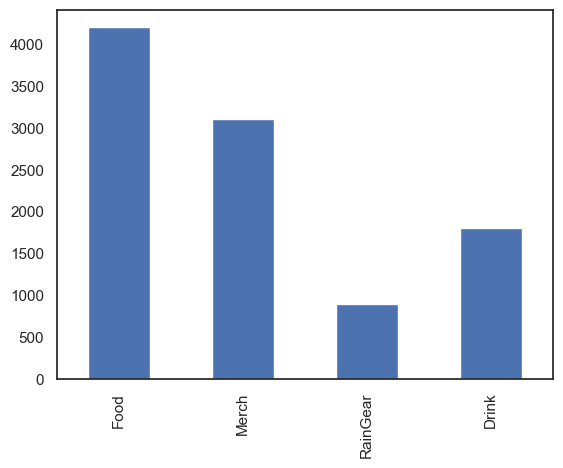

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

revenue = pd.Series({'Food': 4200, 'Merch': 3100, 'RainGear': 900, 'Drink': 1800})
revenue.plot(kind='bar')
plt.show()

Everything is technically present and nothing is communicated. Four problems, and they are the four rules:

- No title, so the reader supplies their own interpretation.
- The y-axis says nothing. Dollars? Thousands? Units?
- Bars are in dictionary order, so comparing them takes effort.
- Vertical bars force the reader to tilt their head to read category names.

Same data, fixed:

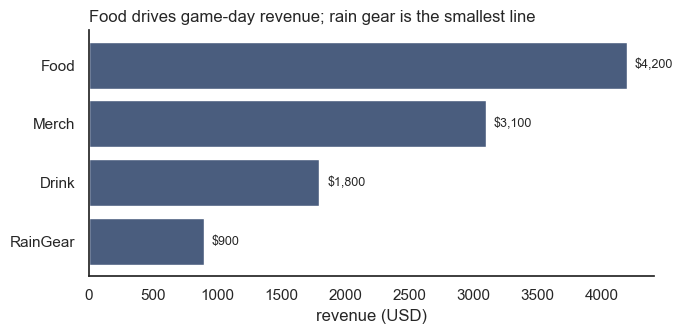

In [ ]:
s = revenue.sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(s.index, s.values, color='#4a5d7e')
ax.set_title('Food drives game-day revenue; rain gear is the smallest line',
             loc='left', fontsize=12)
ax.set_xlabel('revenue (USD)')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
for y, v in enumerate(s.values):
    ax.text(v + 60, y, f'${v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

Sorted so the ranking is instant, horizontal so the labels read left to right, titled with the finding, unit named, and the values labeled so nobody has to squint at gridlines. Removing the top and right spines is not decoration — it takes ink off the page that was not carrying information.

The four things we fixed (title, axis label, spines, tight layout) are the same every time, which is why the setup cell wraps them in `finish()`. From here on the recipes call it.

### Worked example — time, and the annotation that carries the point

A line chart of orders by hour is fine. What makes it an argument is marking the moment that explains the shape.

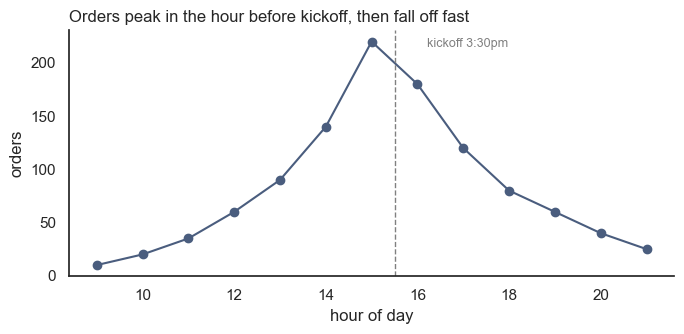

In [ ]:
hours = np.arange(9, 22)
orders = np.array([10, 20, 35, 60, 90, 140, 220, 180, 120, 80, 60, 40, 25])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(hours, orders, marker='o', color='#4a5d7e')
ax.axvline(15.5, ls='--', color='gray', lw=1)
ax.annotate('kickoff 3:30pm', xy=(15.5, 225), xytext=(16.2, 215),
            fontsize=9, color='gray')
ax.set_title('Orders peak in the hour before kickoff, then fall off fast',
             loc='left', fontsize=12)
ax.set_xlabel('hour of day')
ax.set_ylabel('orders')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

The staffing decision falls straight out of that chart: put people on at 2pm, not 4pm. That is what "decision-ready" means — somebody can act without asking you a follow-up question.

### Four mistakes that will cost you points

**1. A truncated y-axis.** Starting a bar chart's axis above zero exaggerates differences. On a line chart it can be reasonable; on bars it is misleading, because the bar's *length* is the thing being compared.

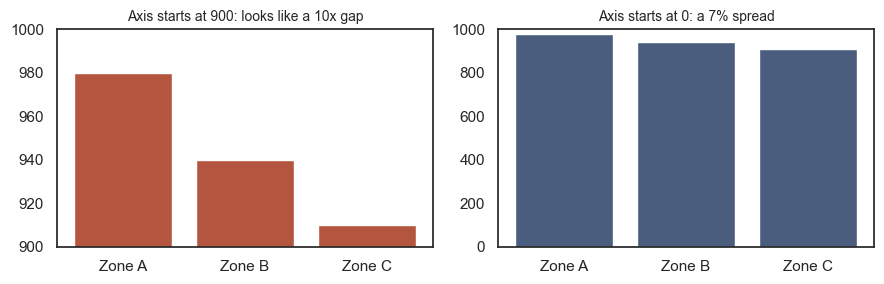

In [ ]:
small = pd.Series({'Zone A': 980, 'Zone B': 940, 'Zone C': 910})

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].bar(small.index, small.values, color='#b4553f')
axes[0].set_ylim(900, 1000)
axes[0].set_title('Axis starts at 900: looks like a 10x gap', fontsize=10)
axes[1].bar(small.index, small.values, color='#4a5d7e')
axes[1].set_ylim(0, 1000)
axes[1].set_title('Axis starts at 0: a 7% spread', fontsize=10)
plt.tight_layout()
plt.show()

**2. Overplotting.** Hundreds of points on a scatter turn into a blob. Transparency and smaller markers recover the shape.

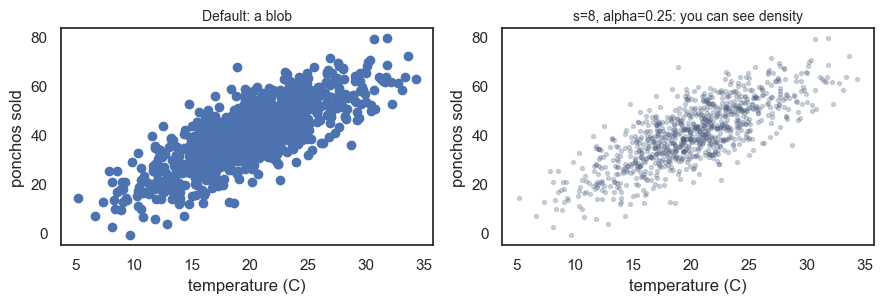

In [ ]:
rng = np.random.default_rng(12)
x = rng.normal(20, 5, 900)
y = x * 2 + rng.normal(0, 8, 900)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].scatter(x, y)
axes[0].set_title('Default: a blob', fontsize=10)
axes[1].scatter(x, y, s=8, alpha=0.25, color='#4a5d7e')
axes[1].set_title('s=8, alpha=0.25: you can see density', fontsize=10)
for ax in axes:
    ax.set_xlabel('temperature (C)')
    ax.set_ylabel('ponchos sold')
plt.tight_layout()
plt.show()

**3. Comparing raw counts across different-sized groups.** Zone A has three times the foot traffic, so of course it sells more. Divide by the thing that makes them different and the chart starts answering the real question.

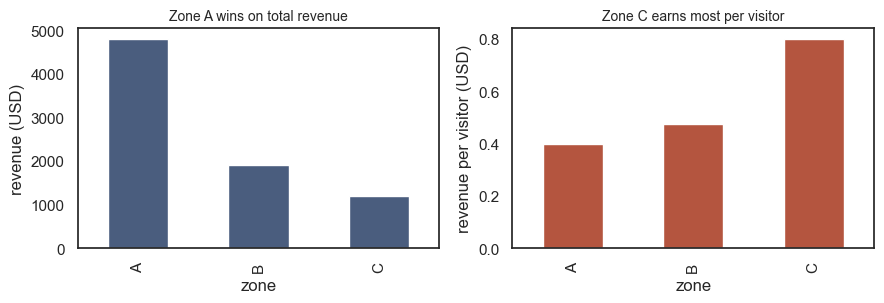

In [ ]:
zones = pd.DataFrame({
    'zone': ['A', 'B', 'C'],
    'revenue': [4800, 1900, 1200],
    'foot_traffic': [12000, 4000, 1500],
}).set_index('zone')
zones['revenue_per_visitor'] = zones['revenue'] / zones['foot_traffic']

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
zones['revenue'].plot(kind='bar', ax=axes[0], color='#4a5d7e')
axes[0].set_title('Zone A wins on total revenue', fontsize=10)
axes[0].set_ylabel('revenue (USD)')
zones['revenue_per_visitor'].plot(kind='bar', ax=axes[1], color='#b4553f')
axes[1].set_title('Zone C earns most per visitor', fontsize=10)
axes[1].set_ylabel('revenue per visitor (USD)')
plt.tight_layout()
plt.show()

Two opposite-looking conclusions from the same data, and both are true. Which one you show depends on the decision: total revenue for "where is our money," revenue per visitor for "where should we add a second cart."

**4. Forgetting `plt.tight_layout()`.** Labels get clipped, and a clipped chart in a presentation looks careless. Make it the last line before `plt.show()` every time. The `finish()` helper from the setup cell does it for you.

---

## The cookbook

Every recipe has the same shape: **when to use it**, **what makes it good**, a cell you can copy, and **what to swap** to use your own data. The cells use the sample data from the setup cell (`df`, `by_cat`, `per_game`, `orders_hour`, `hourly_rain`). To use your own, change the DataFrame and the column names. Nothing else.

One habit runs through all of them: **the title is computed from the data**, in an f-string, so the number in the title cannot drift away from the number in the chart.

### Recipe 1 — Compare categories: a sorted horizontal bar

**Use it when** the question is "which is biggest, and by how much?"

**What makes it good:** sorted, so the ranking is instant. The bars start at zero. The values are written on the bars, so nobody needs gridlines. The names read left to right. The title says the finding.

matplotlib first. You draw each piece yourself, which is why it is the one to learn first.

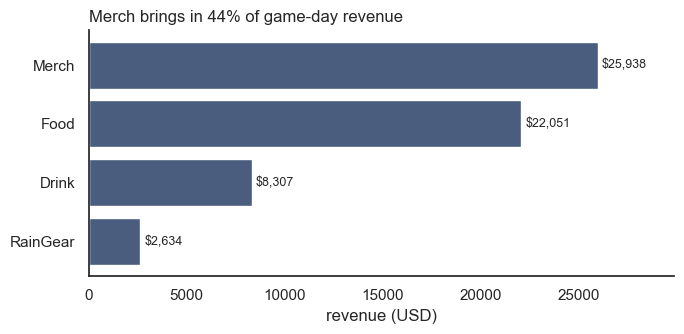

In [ ]:
s = by_cat.sort_values()                                   # smallest first, so the biggest ends up on top
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(s.index, s.values, color=BLUE)
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in s.values], padding=3, fontsize=9)
ax.set_xlim(0, s.max() * 1.15)                             # room at the end for the labels
finish(ax, f'{s.idxmax()} brings in {s.max() / s.sum():.0%} of game-day revenue', xlabel='revenue (USD)')
plt.show()

The same chart in seaborn. `sns.barplot` can do the group-by for you: give it the raw order-level DataFrame and tell it to sum. Seaborn draws on a matplotlib axes, so `finish()` works on the result.

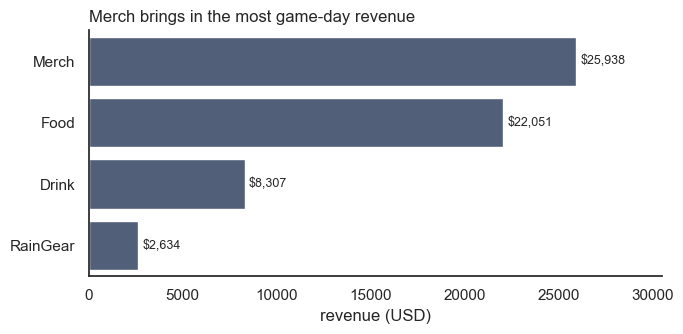

In [ ]:
order = df.groupby('category')['revenue'].sum().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(data=df, y='category', x='revenue', estimator='sum', errorbar=None,
            order=order, color=BLUE, ax=ax)
ax.bar_label(ax.containers[0], labels=[f'${v:,.0f}' for v in ax.containers[0].datavalues], padding=3, fontsize=9)
ax.set_xlim(0, ax.get_xlim()[1] * 1.12)
finish(ax, f'{order[0]} brings in the most game-day revenue', xlabel='revenue (USD)', ylabel='')
plt.show()

**Swap in your data:** `by_cat` or `df`, and the column names `'category'` and `'revenue'`. For counts instead of dollars, use `.size()` in the first version, or `estimator='count'` in the second.

**Watch out:** if the category names are long, keep the bars horizontal. If you have more than about ten categories, show the top eight and say so in the title.

### Recipe 2 — Color carries the message: highlight one bar

**Use it when** one bar is the whole point.

**What makes it good:** every bar is the same muted gray except the one the title is about, which gets a strong color. The reader's eye goes where your sentence goes. One highlight color, never a rainbow. When values go negative, draw a zero line.

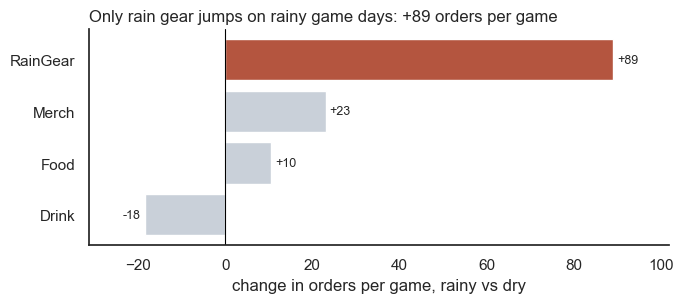

In [ ]:
change = (per_game['rain'] - per_game['dry']).sort_values()      # extra orders per game on a rainy day
colors = [RUST if c == 'RainGear' else GRAY for c in change.index]

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(change.index, change.values, color=colors)
ax.axvline(0, color='black', lw=0.8)
ax.bar_label(bars, labels=[f'{v:+.0f}' for v in change.values], padding=3, fontsize=9)
ax.margins(x=0.12)
finish(ax, f"Only rain gear jumps on rainy game days: +{change['RainGear']:.0f} orders per game",
       xlabel='change in orders per game, rainy vs dry')
plt.show()

**Swap in your data:** the Series being plotted, and the name in the `if c == 'RainGear'` test.

### Recipe 3 — Change over time: lines, labeled directly

**Use it when** the x-axis is time: hour of day, date, game number.

**What makes it good:** time runs left to right. A handful of lines at most. The names sit at the line itself, so nobody has to match colors to a legend. The moment that explains the shape is marked.

Seaborn's `lineplot` draws one line per value of `hue`. Matplotlib adds the labels and the marker.

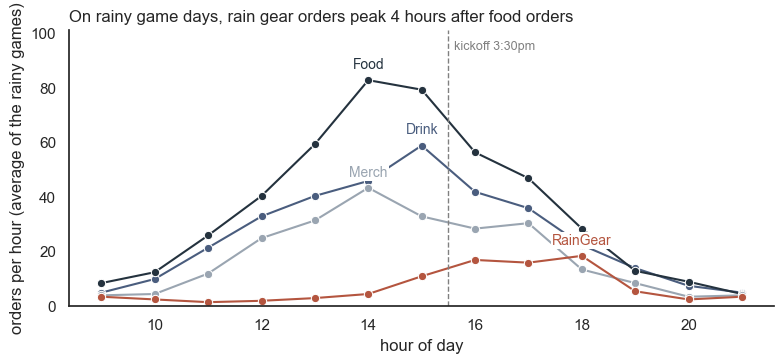

In [ ]:
rainy_days = df[df['weather'] == 'rain']
rainy = (rainy_days.groupby(['category', 'hour']).size() / rainy_days['game'].nunique()).rename('orders').reset_index()
palette = {'Food': '#24323E', 'Drink': BLUE, 'Merch': '#9aa5b1', 'RainGear': RUST}

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.lineplot(data=rainy, x='hour', y='orders', hue='category', palette=palette, marker='o', legend=False, ax=ax)

peaks = rainy.loc[rainy.groupby('category')['orders'].idxmax()]     # label each line just above its peak
for _, p in peaks.iterrows():
    ax.text(p['hour'], p['orders'] + 3, p['category'], color=palette[p['category']], fontsize=10, ha='center', va='bottom',
            bbox=dict(fc='white', ec='none', pad=1))

ax.set_ylim(0, rainy['orders'].max() * 1.22)
ax.axvline(15.5, ls='--', color='gray', lw=1)
ax.text(15.6, ax.get_ylim()[1] * 0.96, 'kickoff 3:30pm', fontsize=9, color='gray', va='top')

gap = int(peaks.set_index('category').loc['RainGear', 'hour'] - peaks.set_index('category').loc['Food', 'hour'])
finish(ax, f"On rainy game days, rain gear orders peak {gap} hour{'s' if gap != 1 else ''} after food orders",
       xlabel='hour of day', ylabel='orders per hour (average of the rainy games)')
plt.show()

**Swap in your data:** the DataFrame, `x`, `y`, and `hue`. Keep `legend=False` and the labels loop.

**Watch out:** more than four or five lines turns into spaghetti. Gray out the ones that are not the point, or use Recipe 9 and draw one small chart per group.

### Recipe 4 — Make a chart decision-ready: annotate it

**Use it when** the chart has a shape and the audience needs the "so what."

**What makes it good:** the reader never has to ask a follow-up question. Mark the thing that explains the shape (kickoff), shade the window that matters, draw the threshold the decision depends on, and point at the peak. Five matplotlib calls cover it.

| You want to | Call |
|---|---|
| Draw a vertical or horizontal reference line | `ax.axvline(x)`, `ax.axhline(y)` |
| Shade a stretch of the axis | `ax.axvspan(x1, x2, alpha=0.15)` |
| Write text at a point | `ax.text(x, y, 'words')` |
| Point an arrow at something | `ax.annotate('words', xy=(x, y), xytext=(x2, y2), arrowprops=dict(arrowstyle='->'))` |

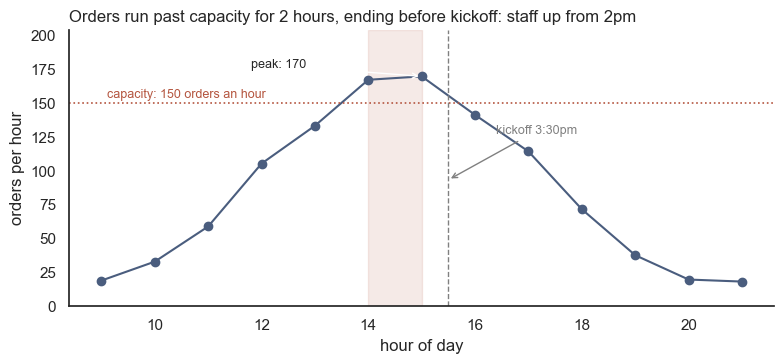

In [ ]:
per_hour = df.groupby('hour').size() / df['game'].nunique()         # orders per hour, average game
CAPACITY = 150                                                      # example: what the stands can serve in an hour
over = per_hour[per_hour > CAPACITY]
peak_hour = per_hour.idxmax()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(per_hour.index, per_hour.values, marker='o', color=BLUE)
ax.axvspan(over.index.min(), over.index.max(), color=RUST, alpha=0.12)                # the hours over capacity
ax.axhline(CAPACITY, ls=':', color=RUST, lw=1.2)
ax.text(9.1, CAPACITY + 4, f'capacity: {CAPACITY} orders an hour', color=RUST, fontsize=9)
ax.axvline(15.5, ls='--', color='gray', lw=1)
ax.annotate('kickoff 3:30pm', xy=(15.5, per_hour.max() * 0.55), xytext=(16.4, per_hour.max() * 0.75),
            arrowprops=dict(arrowstyle='->', color='gray'), fontsize=9, color='gray')
ax.annotate(f'peak: {per_hour.max():.0f}', xy=(peak_hour, per_hour.max()), xytext=(peak_hour - 3.2, per_hour.max() + 6),
            arrowprops=dict(arrowstyle='->'), fontsize=9)
ax.set_ylim(0, per_hour.max() * 1.2)
finish(ax, f'Orders run past capacity for {len(over)} hours, ending before kickoff: staff up from {over.index.min() - 12}pm',
       xlabel='hour of day', ylabel='orders per hour')
plt.show()

**Swap in your data:** the Series, the threshold, and the x positions of your reference lines.

**Watch out:** every annotation has to earn its place. If it does not change what the reader concludes, delete it.

### Recipe 5 — Compare groups side by side: grouped bars

**Use it when** you have two or three groups to compare across the same categories (dry vs rain, this year vs last).

**What makes it good:** the two bars you are comparing sit next to each other. Two colors, and only two. A legend only if the colors are not obvious.

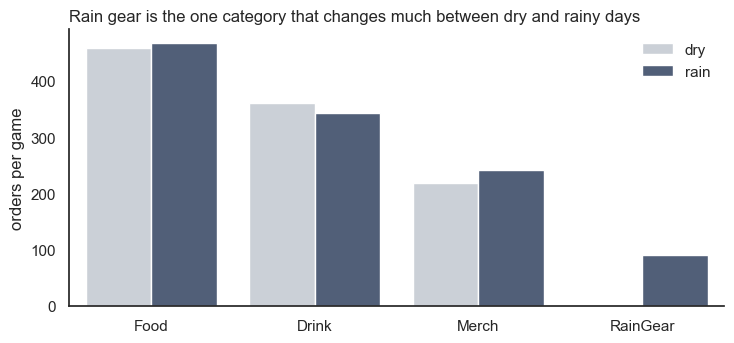

In [ ]:
per_game_long = per_game.reset_index().melt(id_vars='category', var_name='weather', value_name='orders_per_game')
order = per_game['dry'].sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(7.5, 3.6))
sns.barplot(data=per_game_long, x='category', y='orders_per_game', hue='weather', order=order,
            palette={'dry': GRAY, 'rain': BLUE}, ax=ax)
ax.legend(title=None, frameon=False)
finish(ax, 'Rain gear is the one category that changes much between dry and rainy days', xlabel='', ylabel='orders per game')
plt.show()

**Swap in your data:** the long-format table, and the column names for `x`, `y`, and `hue`.

### Recipe 6 — Parts of a whole over time: stacked area

**Use it when** the *total* over time matters as much as the parts, and you have a few parts.

**What makes it good:** the top edge is the total, the bands are the parts. Keep it to four or five bands, and put the biggest on the bottom so its shape is readable. If the question is how the parts compare with each other, use grouped bars instead.

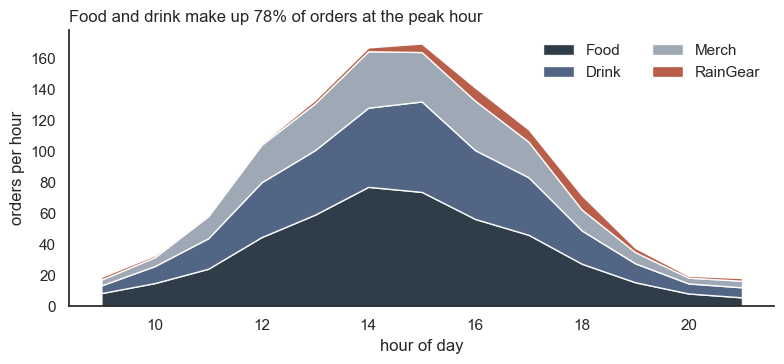

In [ ]:
stack = df.groupby(['hour', 'category']).size().unstack() / df['game'].nunique()      # orders per hour, by category
stack = stack[['Food', 'Drink', 'Merch', 'RainGear']]                                  # biggest first = bottom band
share_at_peak = stack.loc[stack.sum(axis=1).idxmax(), ['Food', 'Drink']].sum() / stack.sum(axis=1).max()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.stackplot(stack.index, stack.T.values, labels=stack.columns,
             colors=['#24323E', BLUE, '#9aa5b1', RUST], alpha=0.95)
ax.legend(loc='upper right', frameon=False, ncols=2)
finish(ax, f'Food and drink make up {share_at_peak:.0%} of orders at the peak hour',
       xlabel='hour of day', ylabel='orders per hour')
plt.show()

**Swap in your data:** the `groupby` keys, and the column order in `stack[[...]]`.

### Recipe 7 — Do two numbers move together: scatter with a trend line

**Use it when** you have two numbers measured on the same rows, and the question is whether one goes with the other.

**What makes it good:** each point is one row. The trend line shows direction without hiding the points. The title states the strength (`r`) **and how many points it rests on**. Seaborn's `regplot` draws both in one call.

If you have hundreds of points, lower `alpha` and `s` so you can see density (see the overplotting mistake above). To bring in a third variable, `sns.scatterplot(..., hue='weather', size='orders')`.

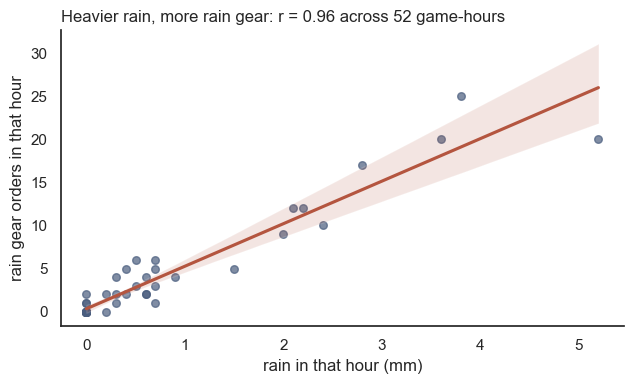

In [ ]:
r = hourly_rain['rain_mm'].corr(hourly_rain['raingear_orders'])

fig, ax = plt.subplots(figsize=(6.5, 4))
sns.regplot(data=hourly_rain, x='rain_mm', y='raingear_orders', ax=ax,
            scatter_kws={'s': 30, 'alpha': 0.7, 'color': BLUE}, line_kws={'color': RUST})
finish(ax, f'Heavier rain, more rain gear: r = {r:.2f} across {len(hourly_rain)} game-hours',
       xlabel='rain in that hour (mm)', ylabel='rain gear orders in that hour')
plt.show()

**Swap in your data:** the DataFrame and the two column names.

**Watch out:** a strong `r` is not a cause. And never report one from three or four points.

### Recipe 8 — How one number is distributed: histogram and box plot

**Use it when** a total or an average would hide the shape: how big is a typical order, and how big is a big one?

**What makes it good:** the histogram shows the shape; a line at the median gives the reader a number to hold. The box plot compares distributions across groups: the box is the middle half of the orders, the line is the median, the dots are unusually large orders.

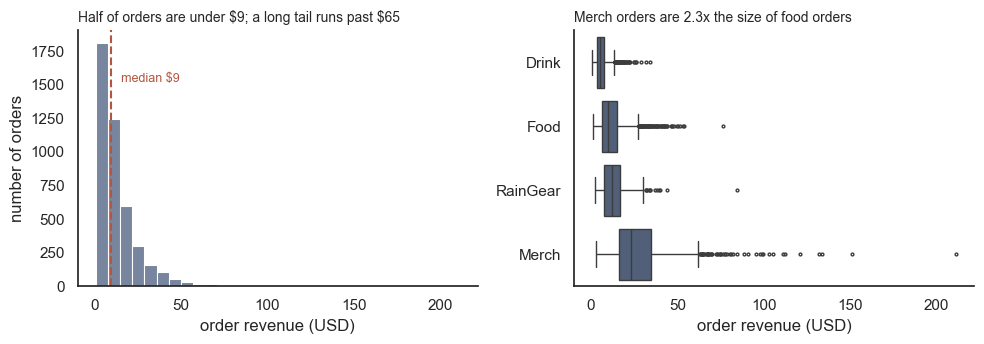

In [ ]:
median, p99 = df['revenue'].median(), df['revenue'].quantile(0.99)
med_by_cat = df.groupby('category')['revenue'].median()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

sns.histplot(data=df, x='revenue', bins=30, color=BLUE, ax=axes[0])
axes[0].axvline(median, color=RUST, ls='--')
axes[0].text(median + 6, axes[0].get_ylim()[1] * 0.8, f'median ${median:.0f}', color=RUST, fontsize=9)
finish(axes[0], f'Half of orders are under ${median:.0f}; a long tail runs past ${p99:.0f}',
       xlabel='order revenue (USD)', ylabel='number of orders', fontsize=10)

order = med_by_cat.sort_values().index
sns.boxplot(data=df, x='revenue', y='category', order=order, color=BLUE, fliersize=2, ax=axes[1])
finish(axes[1], f"Merch orders are {med_by_cat['Merch'] / med_by_cat['Food']:.1f}x the size of food orders",
       xlabel='order revenue (USD)', ylabel='', fontsize=10)
plt.show()

**Swap in your data:** the column name. For a smoother outline use `sns.histplot(..., kde=True)`. For the box plot's cousin that shows the whole shape, use `sns.violinplot`.

**Watch out:** a histogram's shape changes with `bins`. Try two or three values before you believe it.

### Recipe 9 — Two categories against each other: heatmap

**Use it when** you have a grid (zone by hour, store by week, category by category) and want the pattern, not each number.

**What makes it good:** one color scale, light for low and dark for high, with the numbers written in the cells so nobody guesses. Rows and columns in an order that means something (hours run left to right). Seaborn's `heatmap` wants a **wide** table, so make one with `pivot_table`.

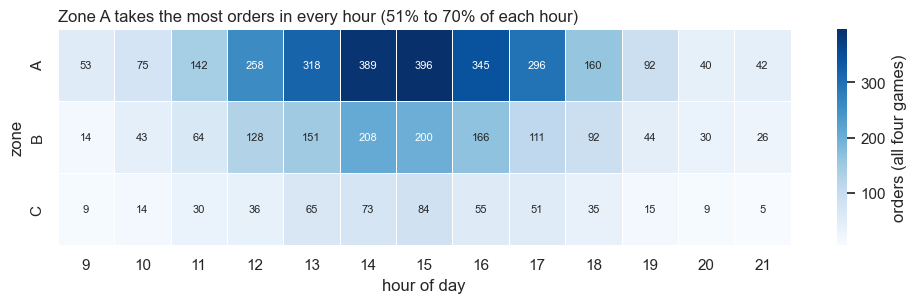

In [ ]:
grid = df.pivot_table(index='zone', columns='hour', values='revenue', aggfunc='size')   # orders in each zone and hour
share_a = grid.loc['A'] / grid.sum()

fig, ax = plt.subplots(figsize=(10, 3.2))
sns.heatmap(grid, cmap='Blues', annot=True, fmt='d', linewidths=0.5, annot_kws={'fontsize': 8},
            cbar_kws={'label': 'orders (all four games)'}, ax=ax)
finish(ax, f'Zone A takes the most orders in every hour ({share_a.min():.0%} to {share_a.max():.0%} of each hour)',
       xlabel='hour of day', ylabel='zone')
plt.show()

A different use: a **correlation heatmap** shows which things rise and fall together. Use a diverging palette centered on zero, so positive and negative look different, and fix the scale to -1 to 1.

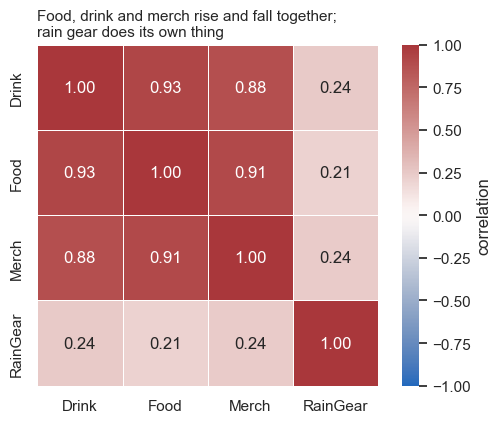

In [ ]:
corr = (df.pivot_table(index=['game', 'hour'], columns='category', values='revenue', aggfunc='size')
          .corr())                                            # correlation of hourly order counts between categories

fig, ax = plt.subplots(figsize=(5.5, 4.4))
sns.heatmap(corr, cmap='vlag', vmin=-1, vmax=1, center=0, annot=True, fmt='.2f', square=True,
            linewidths=0.5, cbar_kws={'label': 'correlation'}, ax=ax)
finish(ax, 'Food, drink and merch rise and fall together;\nrain gear does its own thing', xlabel='', ylabel='', fontsize=11)
plt.show()

**Swap in your data:** the pivot's `index`, `columns`, and `values`. For a grid of totals use `aggfunc='sum'`; for averages, `'mean'`.

### Recipe 10 — The same chart, once per group: small multiples

**Use it when** you would otherwise draw too many lines on one chart. Same axes, one small chart per group.

**What makes it good:** every panel uses the same scale, so you can compare them by eye. Seaborn's `relplot` is the one-line version: `col='game'` means one panel per game, and `col_wrap` says how many per row. The color can carry a second variable.

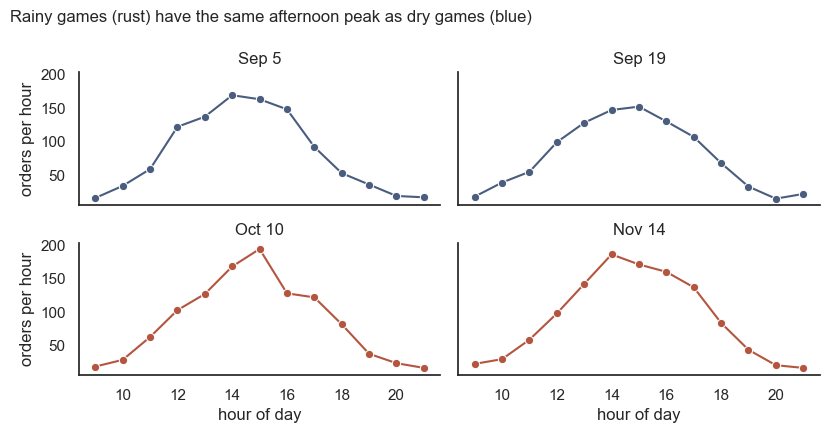

In [ ]:
g = sns.relplot(data=orders_hour, x='hour', y='orders', col='game', col_order=list(GAMES), col_wrap=2, kind='line',
                hue='weather', palette={'dry': BLUE, 'rain': RUST}, marker='o',
                height=2.2, aspect=1.9, legend=False)
g.set_titles('{col_name}')
g.set_axis_labels('hour of day', 'orders per hour')
g.figure.suptitle('Rainy games (rust) have the same afternoon peak as dry games (blue)', x=0.01, ha='left', fontsize=12)
g.figure.tight_layout()
plt.show()

**Swap in your data:** `col=` to the column that defines the groups. In plain matplotlib the same idea is `fig, axes = plt.subplots(1, 4, sharey=True)` and a loop over `axes`.

### Recipe 11 — Two measures on one time axis: stacked panels, not twin axes

**Use it when** you want to show that one thing happened before another: orders and rain, for example.

**What makes it good:** two panels that share the x-axis, so the same hour lines up top and bottom. Do not put two different y-axes on one chart (`twinx`). They invite the reader to see a relationship that the choice of scale made up.

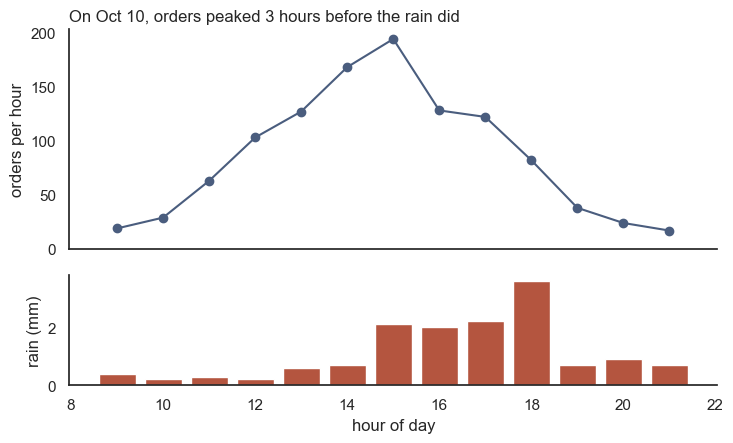

In [ ]:
game = 'Oct 10'
orders_g = orders_hour[orders_hour['game'] == game].set_index('hour')['orders']
rain_g = hourly_rain[hourly_rain['game'] == game].set_index('hour')['rain_mm']
lag = rain_g.idxmax() - orders_g.idxmax()

fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(7.5, 4.6), gridspec_kw={'height_ratios': [2, 1]})
top.plot(orders_g.index, orders_g.values, marker='o', color=BLUE)
top.set_ylim(0, None)
top.set_ylabel('orders per hour')
bottom.bar(rain_g.index, rain_g.values, color=RUST, width=0.8)
bottom.set_ylabel('rain (mm)')
bottom.set_xlabel('hour of day')
for ax in (top, bottom):
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
top.set_title(f'On {game}, orders peaked {lag} hours before the rain did', loc='left', fontsize=12)
fig.tight_layout()
plt.show()

**Swap in your data:** the two Series, and the title's finding.

### Recipe 12 — Make the axis say what it means: units, percents, dates

**Use it when** the tick labels are bare numbers. "Revenue" is not a unit; "revenue (USD)" is, and `$24,000` reads faster than `24000`.

Three formatters cover almost everything. Each is one line on the axis.

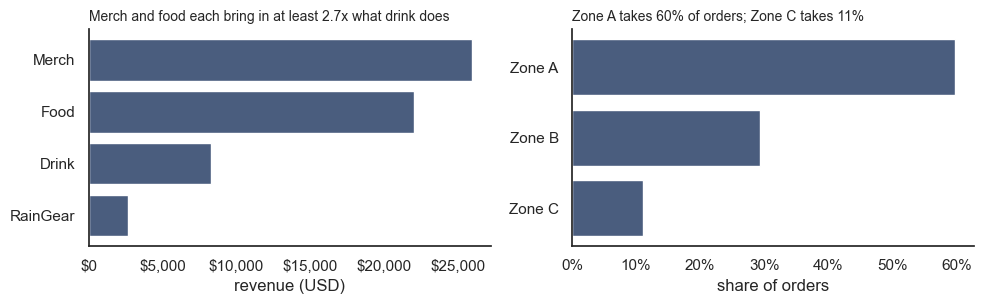

In [ ]:
dollars = FuncFormatter(lambda v, _: f'${v:,.0f}')          # 24000 -> $24,000

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))

s = by_cat.sort_values()
axes[0].barh(s.index, s.values, color=BLUE)
axes[0].xaxis.set_major_formatter(dollars)
finish(axes[0], f'Merch and food each bring in at least {s[["Merch", "Food"]].min() / s["Drink"]:.1f}x what drink does',
       xlabel='revenue (USD)', fontsize=10)

zone_share = df['zone'].value_counts(normalize=True).sort_values()
axes[1].barh('Zone ' + zone_share.index, zone_share.values, color=BLUE)
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0))    # 0.6 -> 60%
finish(axes[1], f"Zone A takes {zone_share['A']:.0%} of orders; Zone C takes {zone_share['C']:.0%}",
       xlabel='share of orders', fontsize=10)
plt.show()

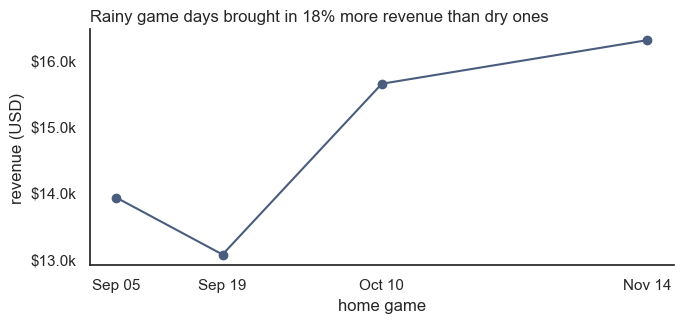

In [ ]:
by_game = df.groupby('game')['revenue'].sum().reindex(list(GAMES))
by_game.index = pd.to_datetime(['2026-09-05', '2026-09-19', '2026-10-10', '2026-11-14'])
rain_avg, dry_avg = by_game[[False, False, True, True]].mean(), by_game[[True, True, False, False]].mean()

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(by_game.index, by_game.values, marker='o', color=BLUE)
ax.set_xticks(by_game.index)                                 # one tick per game, not one per week
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))  # 2026-09-05 -> Sep 05
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'${v / 1000:.1f}k'))
finish(ax, f'Rainy game days brought in {rain_avg / dry_avg - 1:.0%} more revenue than dry ones',
       xlabel='home game', ylabel='revenue (USD)')
plt.show()

Long date or category labels that run into each other: `fig.autofmt_xdate()` for dates, `ax.tick_params(axis='x', rotation=45)` for anything else. Or flip the chart to horizontal bars and the problem goes away.

### Recipe 13 — Color: three kinds, and when to use each

**Use it when** you are about to type a color name.

| Kind | Use for | Seaborn palette |
|---|---|---|
| Sequential (light to dark) | An amount that runs low to high | `'Blues'`, `'viridis'` |
| Diverging (two hues around a middle) | Above or below a baseline, positive or negative | `'vlag'`, `'coolwarm'` |
| Categorical (separate hues) | Separate groups, **five or fewer** | `'colorblind'` |

**What makes it good:** color is doing a job. A highlight color for the one thing that matters, gray for the rest. About one in twelve men cannot tell red from green, so use `'colorblind'` and do not rely on a red/green pair. Avoid rainbow palettes like `'jet'`: they invent boundaries that are not in the data.

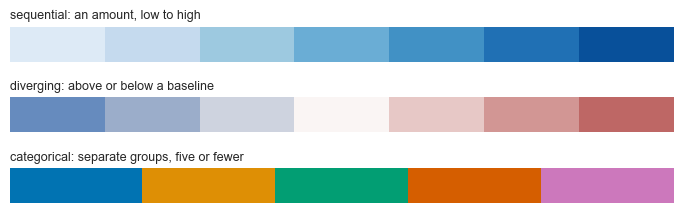

In [ ]:
palettes = {
    "sequential: an amount, low to high": sns.color_palette('Blues', 7),
    "diverging: above or below a baseline": sns.color_palette('vlag', 7),
    "categorical: separate groups, five or fewer": sns.color_palette('colorblind', 5),
}
fig, axes = plt.subplots(len(palettes), 1, figsize=(7, 2.3))
for ax, (name, pal) in zip(axes, palettes.items()):
    ax.imshow([list(range(len(pal)))], cmap=ListedColormap(pal), aspect='auto')
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(name, loc='left', fontsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.tight_layout()
plt.show()

### Recipe 14 — Get it into the deck: save the figure

**Use it when** the chart is done and it is going on a slide.

`savefig` has to come **before** `plt.show()`, because `show` closes the figure. `dpi=200` keeps text sharp when it is projected. `bbox_inches='tight'` trims the white margin. Save PNG for charts; JPG blurs the edges of text. Make the text big enough to read from the back of the room: `plt.rcParams['font.size'] = 13` once at the top of your notebook raises everything.

saved revenue_by_category.png


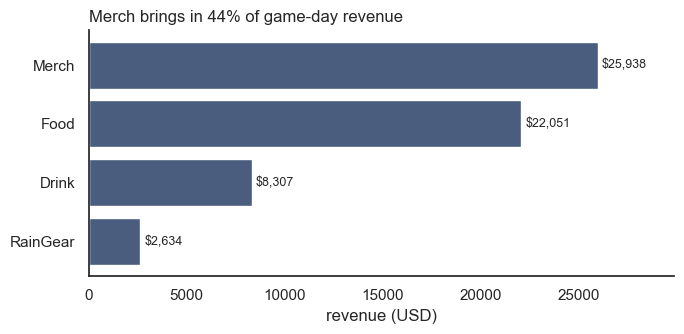

In [ ]:
s = by_cat.sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(s.index, s.values, color=BLUE)
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in s.values], padding=3, fontsize=9)
ax.set_xlim(0, s.max() * 1.15)
finish(ax, f'{s.idxmax()} brings in {s.max() / s.sum():.0%} of game-day revenue', xlabel='revenue (USD)')

fig.savefig('revenue_by_category.png', dpi=200, bbox_inches='tight')    # saved next to this notebook
plt.show()
print('saved revenue_by_category.png')

### The four questions to ask before a chart goes in a deck

1. What is the one sentence this chart proves? If you cannot say it, the chart is not ready.
2. Is that sentence the title?
3. Can someone tell what the units are without asking?
4. Is anything on the page not carrying information?

Wednesday we run those questions against real charts, including some of yours.

---

## Worked examples

Three short ones that put the rules together, using the same small data from earlier in the notebook.

### Worked example 1 — one clean bar chart

Orders per zone: A is 900, B is 400, C is 250. Sorted horizontal bar, a title that states the finding, a labeled axis with the unit, no top or right spine.

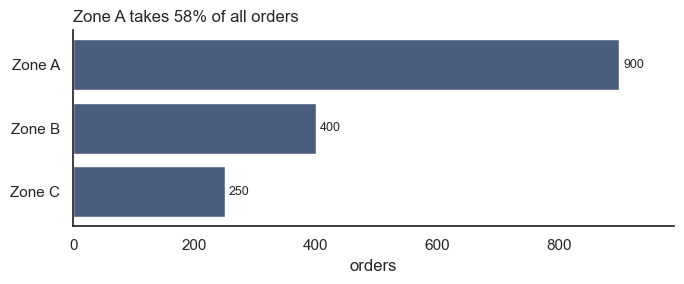

In [ ]:
zone_orders = pd.Series({'A': 900, 'B': 400, 'C': 250}).sort_values()

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh([f'Zone {z}' for z in zone_orders.index], zone_orders.values, color=BLUE)
ax.bar_label(bars, padding=3, fontsize=9)
ax.margins(x=0.1)
finish(ax, f'Zone A takes {zone_orders["A"] / zone_orders.sum():.0%} of all orders', xlabel='orders')
plt.show()

### Worked example 2 — rewrite the titles

Each topic title becomes a claim you can defend from the data earlier in this notebook.

| Topic title | Message title | Where it comes from |
|---|---|---|
| "Revenue by category" | Food and merch bring in nearly three of every four revenue dollars | $4,200 + $3,100 of $10,000 is 73% |
| "Orders by hour" | Orders peak in the hour before kickoff, then fall off fast | 220 orders at 3pm, kickoff at 3:30pm |
| "Revenue by zone" | Zone A wins on total revenue, but Zone C earns the most per visitor | $0.40 per visitor in A, $0.80 in C |

The test for each one: if the reader stopped at the title, would they know what to do differently?

### Worked example 3 — fix a bad chart

Here is a bad chart. Four of today's problems are in it.

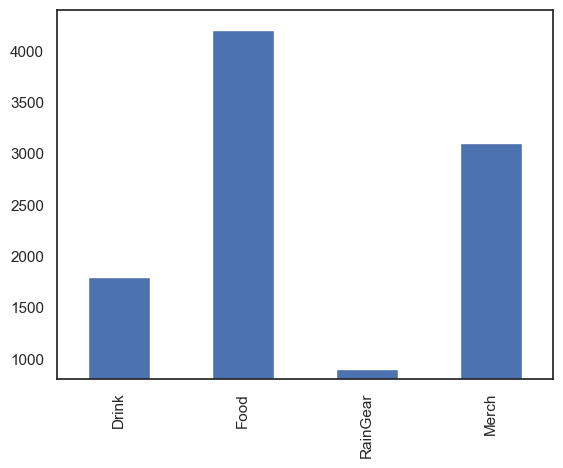

In [ ]:
bad = pd.Series({'Drink': 1800, 'Food': 4200, 'RainGear': 900, 'Merch': 3100})
bad.plot(kind='bar')
plt.ylim(800, 4400)
plt.show()

The four problems:

1. **No title.** The reader has to guess what it is about.
2. **No axis label or unit.** Dollars? Units? Thousands?
3. **Not sorted.** Drink, Food, RainGear, Merch is the order the dictionary happened to be in.
4. **The y-axis starts at 800.** Rain gear (900) looks like it is about to disappear, but it is 21% of food, not 3%. The bar's length is the thing being compared, so the bars have to start at zero.

Fixed:

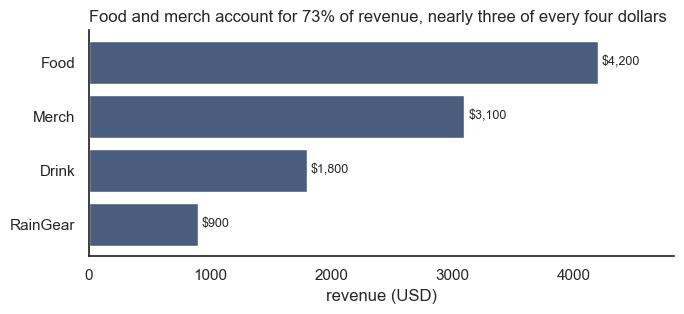

In [ ]:
fixed = bad.sort_values()

fig, ax = plt.subplots(figsize=(7, 3.3))
bars = ax.barh(fixed.index, fixed.values, color=BLUE)
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in fixed.values], padding=3, fontsize=9)
ax.set_xlim(0, fixed.max() * 1.15)
share = (fixed['Food'] + fixed['Merch']) / fixed.sum()
finish(ax, f'Food and merch account for {share:.0%} of revenue, nearly three of every four dollars', xlabel='revenue (USD)')
plt.show()

---

## Cheat sheet

**Pick the chart from the question**

| The question | Chart | Recipe |
|---|---|---|
| Which is biggest? | Sorted horizontal bar | 1, 2 |
| How did it change over time? | Line, labeled directly | 3, 4 |
| How do two groups compare? | Grouped bar | 5 |
| What are the parts of the total? | Stacked area | 6 |
| Do two numbers move together? | Scatter with trend line | 7 |
| What is typical, and what is extreme? | Histogram, box plot | 8 |
| Where is the pattern in a grid? | Heatmap | 9 |
| Too many lines for one chart? | Small multiples | 10 |
| Did one thing happen before another? | Stacked panels | 11 |

**Matplotlib calls you will use every week**

| You want to | Call |
|---|---|
| Set the size | `fig, ax = plt.subplots(figsize=(7, 3.5))` |
| Title, left-aligned | `ax.set_title('the finding', loc='left')` |
| Label the axes | `ax.set_xlabel('revenue (USD)')`, `ax.set_ylabel('orders')` |
| Start an axis at zero | `ax.set_xlim(0, None)` or `ax.set_ylim(0, None)` |
| Put values on bars | `ax.bar_label(bars, padding=3)` |
| Remove top and right lines | `ax.spines['top'].set_visible(False)` |
| Rotate tick labels | `ax.tick_params(axis='x', rotation=45)` |
| Legend with no box, or none | `ax.legend(frameon=False)`, `legend=False` in seaborn |
| Reference line, shaded band | `ax.axvline(x)`, `ax.axvspan(x1, x2, alpha=0.15)` |
| Dollars, percent on an axis | `FuncFormatter(lambda v, _: f'${v:,.0f}')`, `PercentFormatter(1.0)` |
| Bigger text everywhere | `plt.rcParams['font.size'] = 13` |
| Save for a slide | `fig.savefig('name.png', dpi=200, bbox_inches='tight')` |
| Stop clipped labels | `plt.tight_layout()` |

**Before it goes in a deck:** one message, a title that states it, units on the axes, nothing on the page that is not carrying information.